# Домашнее задание 3. Анализ данных сервиса такси

Темы лекций 11-17: NumPy, pandas, чистка данных, объединение таблиц, группировка, визуализация.

Сервис вызова такси предоставил выгрузку поездок за первый квартал 2024 года. Данные сырые, прямо из системы. Проведите анализ и ответьте на 10 вопросов. Каждый вопрос имеет один верный ответ. Выполните расчёт в этом ноутбуке, затем введите ответы в поля на странице задания на платформе.

Данные загружаются напрямую по ссылке, скачивать отдельно не нужно. Прежде чем считать любую цифру, осмотрите данные: типы столбцов, дубликаты, пропуски, форматы записи.

> **Решение.** Все 10 ответов приняты платформой (10 / 10).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

trips = pd.read_csv("hw3_trips.csv")
drivers = pd.read_csv("hw3_drivers.csv")
print(trips.shape, drivers.shape)
trips.head()

(5080, 11) (300, 5)


,trip_id,datetime,city,driver_id,distance_km,duration_min,surge_multiplier,fare_uzs,status,payment_method,rating
0,T004702,2024-02-02 10:30:00,Toshkent,D0244,3.9,11.0,1.0,10 800,completed,cash,5.0
1,T000766,2024-02-18 08:46:00,Samarqand,D0011,2.3,5.0,1.0,8 400,completed,card,4.0
2,T002639,2024-01-26 01:51:00,Toshkent,D0215,14.9,43.0,1.0,27 400,Completed,card,4.5
3,T004022,2024-03-17 19:43:00,Andijon,D0240,3.1,10.0,1.3,19 300,completed,card,3.8
4,T001096,2024-02-12 18:38:00,Samarqand,D0117,5.0,11.0,2.0,38 000,Completed,card,3.8


## Q1. Объём данных

В выгрузке есть полные дубликаты строк. Сколько уникальных поездок остаётся после их удаления? Введите целое число.

In [2]:
# Разведка: типы, пропуски, дубликаты
print(trips.dtypes, end="\n\n")
print(trips.isna().sum(), end="\n\n")
print("Полных дубликатов:", trips.duplicated().sum())

trips = trips.drop_duplicates().reset_index(drop=True)
print("Q1 — уникальных поездок:", len(trips))

trip_id                 str
datetime                str
city                    str
driver_id               str
distance_km         float64
duration_min        float64
surge_multiplier    float64
fare_uzs                str
status                  str
payment_method          str
rating              float64
dtype: object

trip_id               0
datetime              0
city                  0
driver_id             0
distance_km           0
duration_min        101
surge_multiplier      0
fare_uzs            862
status                0
payment_method      760
rating              760
dtype: int64

Полных дубликатов: 80
Q1 — уникальных поездок: 5000


## Q2. Выручка

Какова суммарная выручка по завершённым поездкам, в миллионах UZS (округлите до целого)?

Учтите: столбец `fare_uzs` записан текстом с пробелами, а в столбце `status` один и тот же статус встречается в разном регистре.

In [3]:
# Статус в разном регистре: completed / Completed / COMPLETED
print(trips["status"].value_counts(), end="\n\n")
trips["status"] = trips["status"].str.strip().str.lower()

# fare_uzs — текст вида "10 800"; пропуски остаются NaN
trips["fare"] = pd.to_numeric(trips["fare_uzs"].str.replace(" ", ""), errors="coerce")

completed = trips[trips["status"] == "completed"]
revenue = completed["fare"].sum()
print(f"Выручка: {revenue:,.0f} UZS")
print("Q2 — выручка, млн UZS:", round(revenue / 1e6))

status
completed    2516
Completed    1131
COMPLETED     609
cancelled     379
no_show       136
Cancelled     133
canceled       96
Name: count, dtype: int64

Выручка: 85,871,700 UZS
Q2 — выручка, млн UZS: 86


## Q3. Аномальные тарифы

Среди завершённых поездок, сколько имеют тариф выше `mean + 2 * std`? Используйте NumPy (`np.mean`, `np.std`). Введите целое число.

In [4]:
fares = completed["fare"].dropna().to_numpy()
threshold = np.mean(fares) + 2 * np.std(fares)
print(f"Порог mean + 2*std: {threshold:,.0f} UZS")
print("Q3 — поездок выше порога:", int((fares > threshold).sum()))

Порог mean + 2*std: 43,974 UZS
Q3 — поездок выше порога: 207


## Q4. Час пик

В какой час суток (0-23) совершается больше всего поездок? Постройте линейный график числа поездок по часам и определите пик.

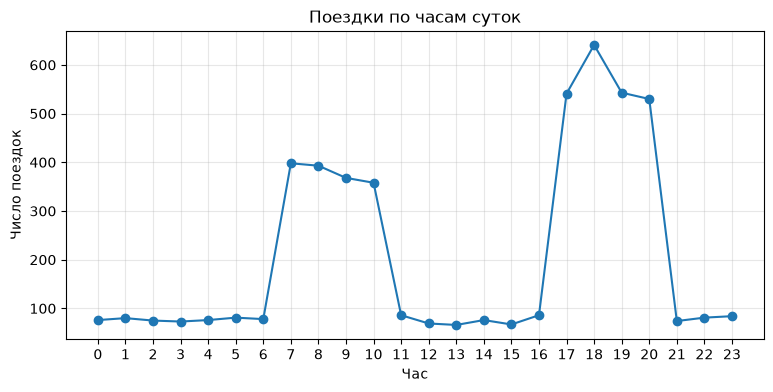

Q4 — час пик: 18


In [5]:
trips["datetime"] = pd.to_datetime(trips["datetime"])
by_hour = trips["datetime"].dt.hour.value_counts().sort_index()

ax = by_hour.plot(marker="o", figsize=(9, 4))
ax.set(title="Поездки по часам суток", xlabel="Час", ylabel="Число поездок", xticks=range(24))
ax.grid(alpha=0.3)
plt.show()

print("Q4 — час пик:", by_hour.idxmax())

## Q5. Город-лидер

В каком городе наибольшая суммарная выручка по завершённым поездкам? Введите название города как в данных.

In [6]:
city_revenue = completed.groupby("city")["fare"].sum().sort_values(ascending=False)
print((city_revenue / 1e6).round(1).rename("млн UZS"), end="\n\n")
print("Q5 — город-лидер:", city_revenue.idxmax())

city
Toshkent     38.8
Andijon      12.7
Samarqand    12.0
Namangan     11.6
Buxoro       10.8
Name: млн UZS, dtype: float64

Q5 — город-лидер: Toshkent


## Q6. Класс автомобиля

Объедините поездки с таблицей водителей по `driver_id`. У какого класса автомобиля самый высокий средний тариф (по завершённым поездкам)? Введите название класса.

In [7]:
merged = completed.merge(drivers[["driver_id", "vehicle_class"]], on="driver_id", how="left")
print("Поездок без водителя в справочнике:", merged["vehicle_class"].isna().sum(), end="\n\n")

class_fare = merged.groupby("vehicle_class")["fare"].mean().sort_values(ascending=False)
print(class_fare.round(0), end="\n\n")
print("Q6 — класс с самым высоким средним тарифом:", class_fare.idxmax())

Поездок без водителя в справочнике: 0

vehicle_class
Business    37889.0
Comfort     24806.0
Economy     16539.0
Name: fare, dtype: float64

Q6 — класс с самым высоким средним тарифом: Business


## Q7. Отмены

Какова доля отменённых поездок (статус `cancelled`) среди всех поездок, в процентах (округлите до целого)? Учтите разный регистр в статусе.

In [8]:
# После приведения к нижнему регистру: cancelled / Cancelled -> cancelled.
# Вариант "canceled" (одна l) — другое написание; по условию считаем только `cancelled`.
print(trips["status"].value_counts(), end="\n\n")

cancel_share = (trips["status"] == "cancelled").mean() * 100
print(f"Доля cancelled: {cancel_share:.2f}%")
print("Q7 — доля отмен, %:", round(cancel_share))

status
completed    4256
cancelled     512
no_show       136
canceled       96
Name: count, dtype: int64

Доля cancelled: 10.24%
Q7 — доля отмен, %: 10


## Q8. Скорость

Какова медианная скорость поездки в км/ч? Скорость = `distance_km / duration_min * 60`. Перед расчётом уберите поездки с нулевой или отрицательной дистанцией и с пропущенной длительностью.

In [9]:
valid = trips[(trips["distance_km"] > 0) & trips["duration_min"].notna()]
speed = valid["distance_km"] / valid["duration_min"] * 60
print("Поездок в расчёте:", len(valid))
print("Q8 — медианная скорость, км/ч:", round(speed.median()))

Поездок в расчёте: 4826
Q8 — медианная скорость, км/ч: 26


## Q9. Способ оплаты

Какой способ оплаты используется чаще всего среди завершённых поездок? Постройте столбчатую диаграмму. Введите значение как в данных.

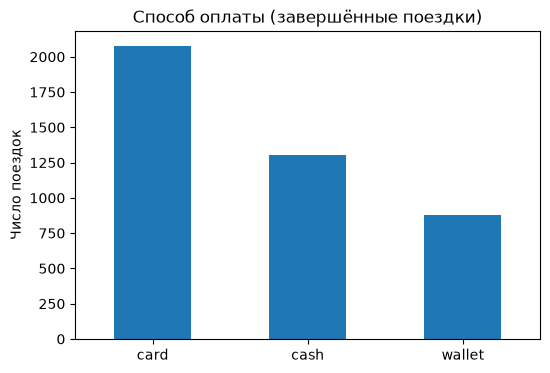

Q9 — самый частый способ оплаты: card


In [10]:
payments = completed["payment_method"].value_counts()

ax = payments.plot.bar(figsize=(6, 4), rot=0)
ax.set(title="Способ оплаты (завершённые поездки)", xlabel="", ylabel="Число поездок")
plt.show()

print("Q9 — самый частый способ оплаты:", payments.idxmax())

## Q10. Длина поездки

Чему равен 90-й перцентиль дистанции поездки (км, округлите до целого)? Используйте только поездки с корректной дистанцией (больше нуля).

In [11]:
distance = trips.loc[trips["distance_km"] > 0, "distance_km"]
p90 = np.percentile(distance, 90)
print(f"90-й перцентиль: {p90:.2f} км")
print("Q10 — 90-й перцентиль дистанции, км:", round(p90))

90-й перцентиль: 10.90 км
Q10 — 90-й перцентиль дистанции, км: 11


## Отправка ответов

Перенесите полученные значения в поля на странице задания на платформе и отправьте до дедлайна.

In [12]:
answers = {
    "Q1": len(trips),
    "Q2": round(revenue / 1e6),
    "Q3": int((fares > threshold).sum()),
    "Q4": by_hour.idxmax(),
    "Q5": city_revenue.idxmax(),
    "Q6": class_fare.idxmax(),
    "Q7": round(cancel_share),
    "Q8": round(speed.median()),
    "Q9": payments.idxmax(),
    "Q10": round(p90),
}
pd.Series(answers, name="ответ").to_frame()

,ответ
Q1,5000
Q2,86
Q3,207
Q4,18
Q5,Toshkent
Q6,Business
Q7,10
Q8,26
Q9,card
Q10,11
